# PS-S3: Trotter Error vs Synthetic Device Noise
An Architectural Study of Quantum Simulation Accuracy

Four logical spins; V2 reference A (5-qubit line) and B (9-qubit heavy-hex-inspired graph). This notebook regenerates the full 108-case grid and all benchmark plots. Use the pinned environment and run all cells from a fresh kernel. Reusable physics, compilation, simulation and plotting live in `src/`.

In [1]:
from pathlib import Path
import json
import numpy as np
from IPython.display import display, Image
from src.problem import hamiltonian, dense_terms, exact_state, trotter_circuit
from src.processors import ROOT, load_processor
from src.metrics import run_benchmark, environment
print(json.dumps(environment(), indent=2))

{
  "python": "3.12.14",
  "platform": "Windows-11-10.0.26200-SP0",
  "packages": {
    "qiskit": "2.5.2",
    "qiskit-aer": "0.17.2",
    "numpy": "2.5.4",
    "scipy": "1.18.1",
    "pandas": "3.0.6",
    "matplotlib": "3.11.2",
    "networkx": "3.7",
    "nbformat": "5.11.1",
    "nbclient": "0.11.0",
    "ipykernel": "7.4.0",
    "pytest": "9.1.1"
  }
}


## Physics and conventions
$H=-\sum_{i=0}^2 Z_iZ_{i+1}-\sum_{i=0}^3X_i$, $J=g=1$, $\hbar=1$. Primary state: |0000>. Qiskit label IIIZ is Z0. $R_P(\theta)=e^{-i\theta P/2}$ gives RX/RZZ angles $-2\Delta t$. Apply ZZ gates first, then X: $U_n(t)=[e^{-iH_Xt/n}e^{-iH_{ZZ}t/n}]^n$. The exact reference uses independent NumPy tensor products and SciPy expm.

In [2]:
hzz, hx = dense_terms()
assert np.allclose(hamiltonian().to_matrix(), hzz+hx)
display(hamiltonian())
print(trotter_circuit(0.5, 1).draw(output='text'))

SparsePauliOp(['IIZZ', 'IZZI', 'ZZII', 'IIIX', 'IIXI', 'IXII', 'XIII'],
              coeffs=[-1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j, -1.+0.j])

              ┌────────┐                    
q_0: ─■───────┤ Rx(-1) ├────────────────────
      │ZZ(-1) └────────┘┌────────┐          
q_1: ─■────────■────────┤ Rx(-1) ├──────────
               │ZZ(-1)  └────────┘┌────────┐
q_2: ──────────■─────────■────────┤ Rx(-1) ├
                         │ZZ(-1)  ├────────┤
q_3: ────────────────────■────────┤ Rx(-1) ├
                                  └────────┘


## Architectures and controlled settings
A is a five-node line; B the exact 12-edge heavy-hex-inspired reference in the V2 guide (page 2). Every link supports both CX directions. Both contain a four-node path. Optimized means SABRE heuristic placement, not a proof of optimality. Fixed placement [0,1,2,3] is label-dependent and not an architecture ranking. Noise: depolarizing lambda=.001 after every rz/sx/x, .005 after cx; readout=.01. Level 1, transpiler and simulator seed 42, 4096 shots; n=1,2,4; nine times from 0 to 2.

In [3]:
expected_edges = {
    'A': {(0,1), (1,2), (2,3), (3,4)},
    'B': {(0,1), (1,2), (1,6), (2,3), (2,6), (2,5),
          (3,4), (4,5), (5,6), (6,7), (6,8), (0,8)},
}
for name in ['A', 'B']:
    cfg = load_processor(name)
    assert {tuple(sorted(edge)) for edge in cfg['undirected_edges']} == expected_edges[name]
    assert set(map(tuple, cfg['directed_cx_edges'])) == {
        direction for a, b in expected_edges[name] for direction in [(a,b), (b,a)]
    }
    print(name, cfg['num_qubits'], cfg['undirected_edges'])

A 5 [[0, 1], [1, 2], [2, 3], [3, 4]]
B 9 [[0, 1], [1, 2], [1, 6], [2, 3], [2, 6], [2, 5], [3, 4], [4, 5], [5, 6], [6, 7], [6, 8], [8, 0]]


## Paired ideal/noisy experiment and exports
Each pair uses the same compiled circuit. The post-routing checkpoint counts SWAPs before native decomposition. Sorted physical outputs are reduced and reordered to logical qubits using the final layout. Every case checks ideal compilation fidelity and shot totals. The density is saved before measurement; readout affects counts, not state fidelity.

In [4]:
results, summary = run_benchmark()
assert len(results) == 108
print('Minimum compiled ideal fidelity:', results.compiled_ideal_fidelity.min())
display(summary.round(6))

Completed A / optimized / n=1: 9/108


Completed A / optimized / n=2: 18/108


Completed A / optimized / n=4: 27/108


Completed A / fixed / n=1: 36/108


Completed A / fixed / n=2: 45/108


...

Completed B / fixed / n=1: 90/108


Completed B / fixed / n=2: 99/108


Completed B / fixed / n=4: 108/108


Minimum compiled ideal fidelity: 0.9999999999999983


,processor,layout_mode,steps,depth,cx_count,one_qubit_count,routing_swaps,trotter_error,gate_noise_shift,readout_shift,total_expected_error,total_sampled_error,algorithm_fidelity,noisy_fidelity_to_trotter,noisy_fidelity_to_exact
0,A,fixed,1,14.0,6.0,23.0,0.0,0.474071,0.009855,0.013018,0.464080,0.468007,0.412778,0.966610,0.400257
1,A,fixed,2,25.0,12.0,46.0,0.0,0.105239,0.010092,0.006562,0.109397,0.111647,0.572892,0.930677,0.536621
2,A,fixed,4,47.0,24.0,92.0,0.0,0.009643,0.014646,0.004844,0.022500,0.024381,0.908469,0.865980,0.787998
3,A,optimized,1,14.0,6.0,23.0,0.0,0.474071,0.009855,0.013018,0.464080,0.470021,0.412778,0.966610,0.400257
4,A,optimized,2,25.0,12.0,46.0,0.0,0.105239,0.010092,0.006562,0.109397,0.109267,0.572892,0.930677,0.536621
5,A,optimized,4,47.0,24.0,92.0,0.0,0.009643,0.014646,0.004844,0.022500,0.024775,0.908469,0.865980,0.787998
6,B,fixed,1,14.0,6.0,23.0,0.0,0.474071,0.009855,0.013018,0.464080,0.468007,0.412778,0.966610,0.400257
7,B,fixed,2,25.0,12.0,46.0,0.0,0.105239,0.010092,0.006562,0.109397,0.111647,0.572892,0.930677,0.536621
8,B,fixed,4,47.0,24.0,92.0,0.0,0.009643,0.014646,0.004844,0.022500,0.024381,0.908469,0.865980,0.787998
9,B,optimized,1,14.0,6.0,23.0,0.0,0.474071,0.009855,0.013018,0.464080,0.467946,0.412778,0.966610,0.400257


## Topologies, accuracy and resource costs
Summary means exclude t=0. Error bars show finite-shot Wilson 95% intervals only. Signed error components can cancel: absolute component sizes must not be added.

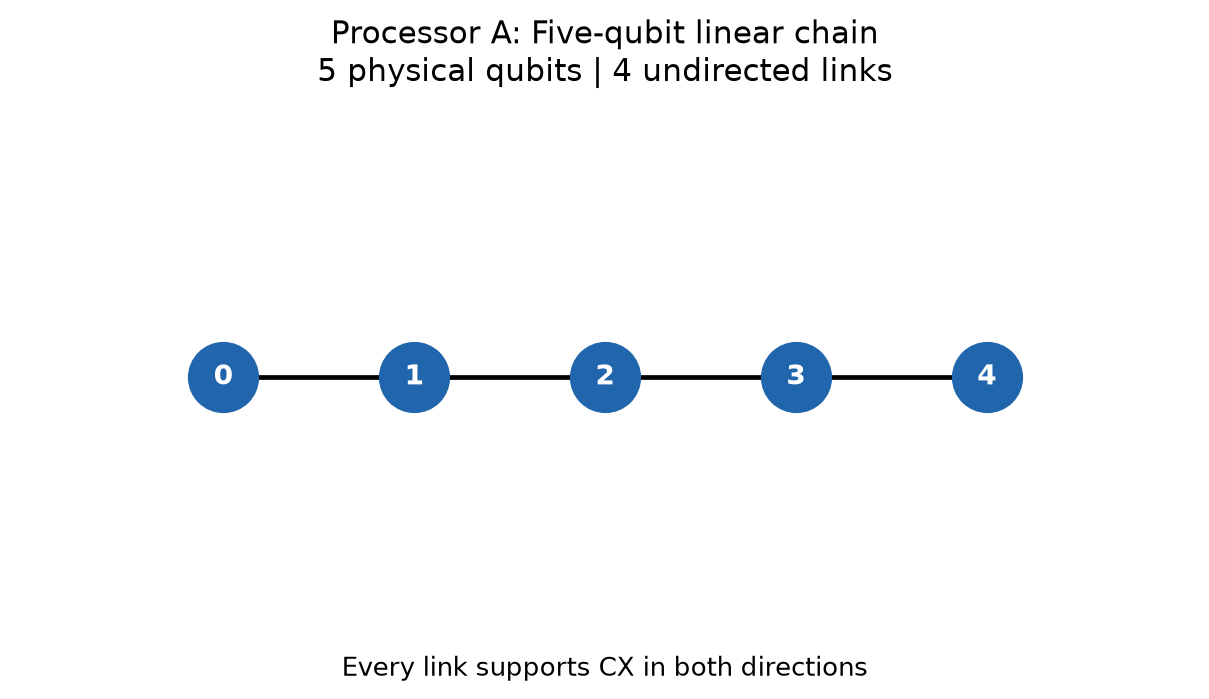

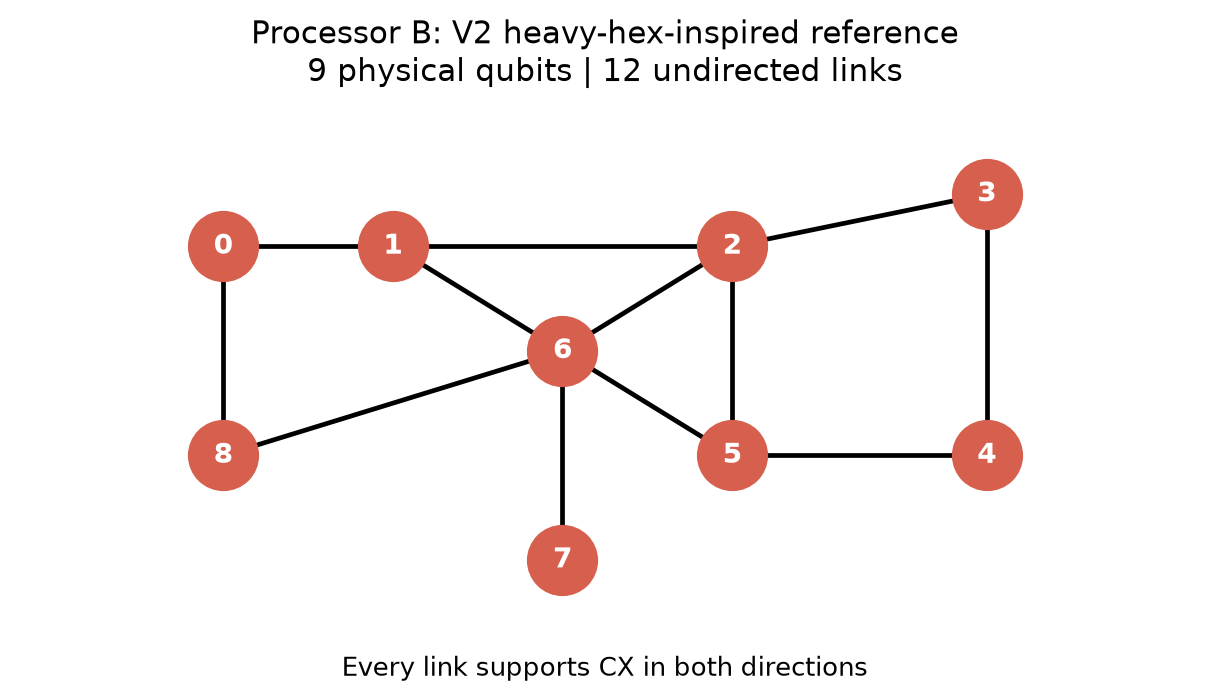

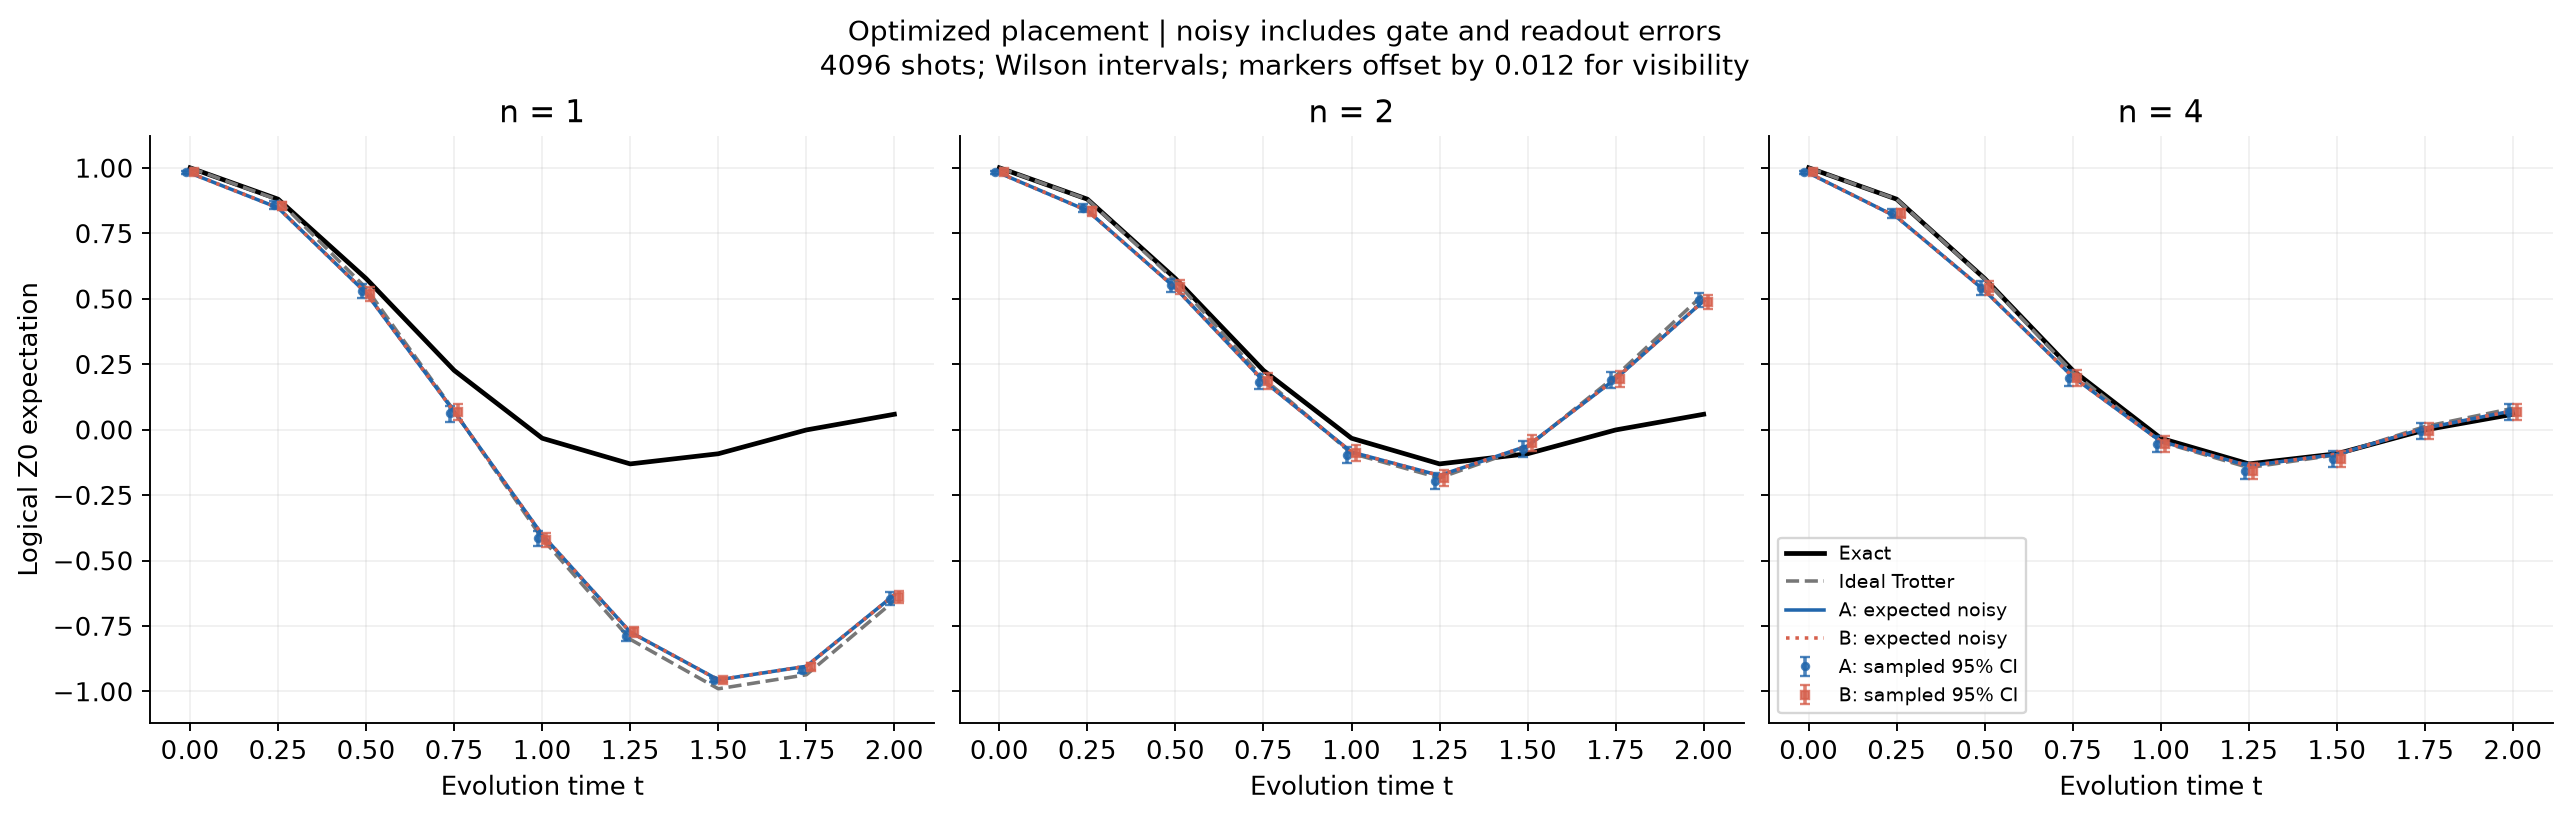

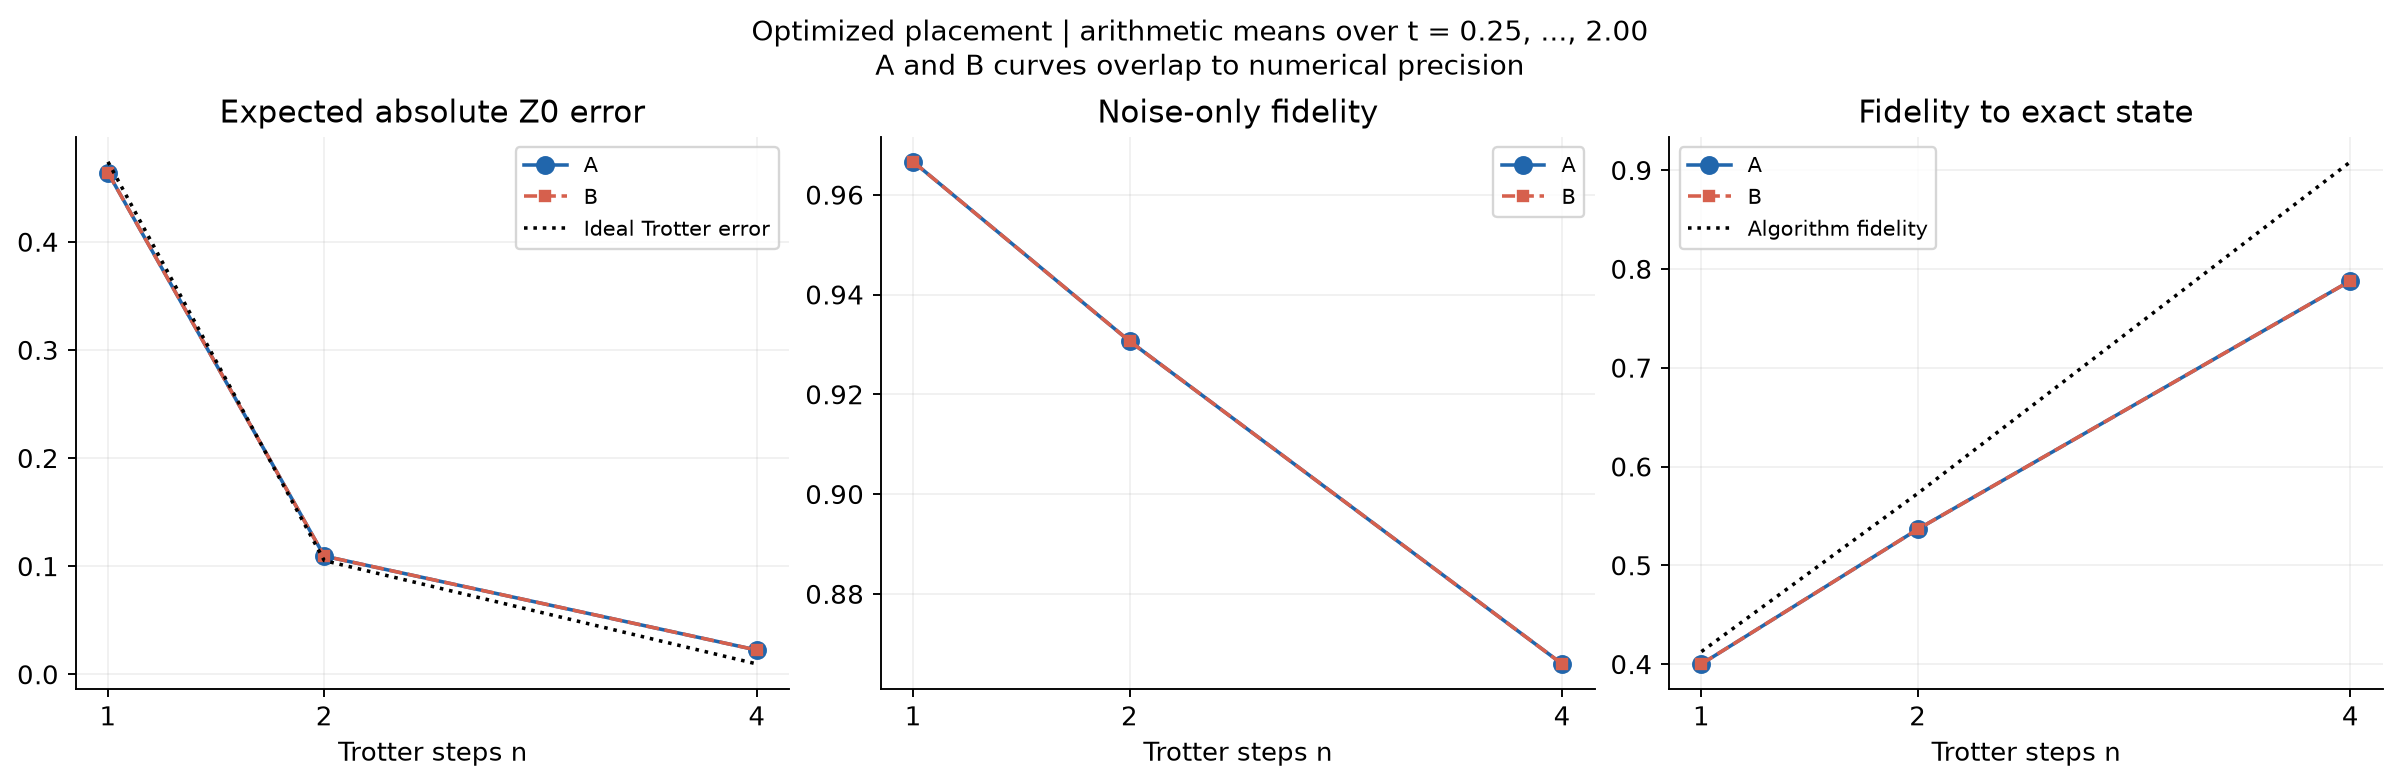

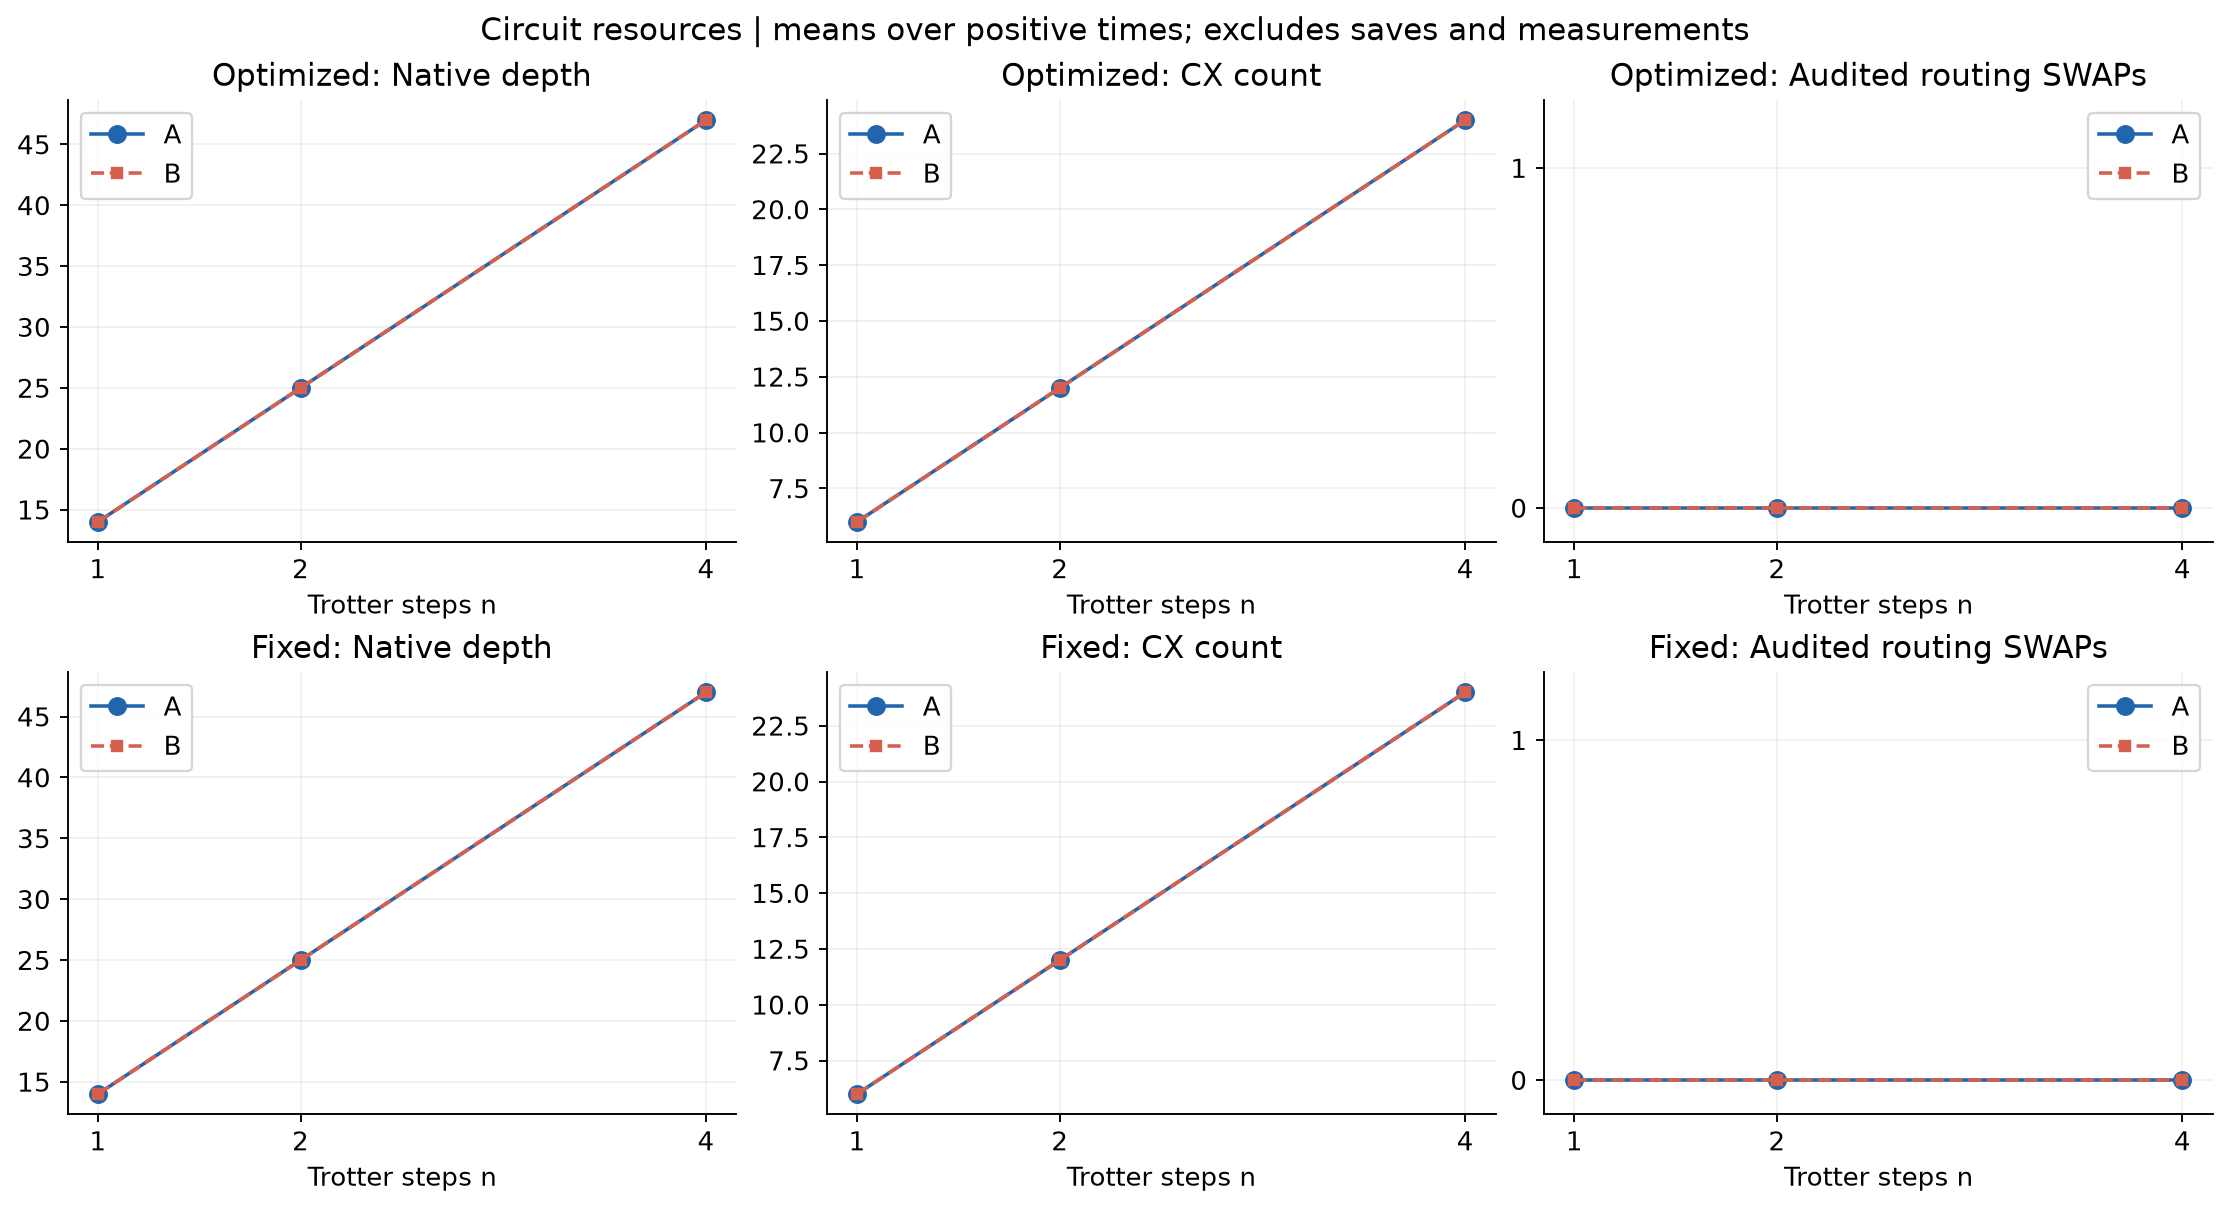

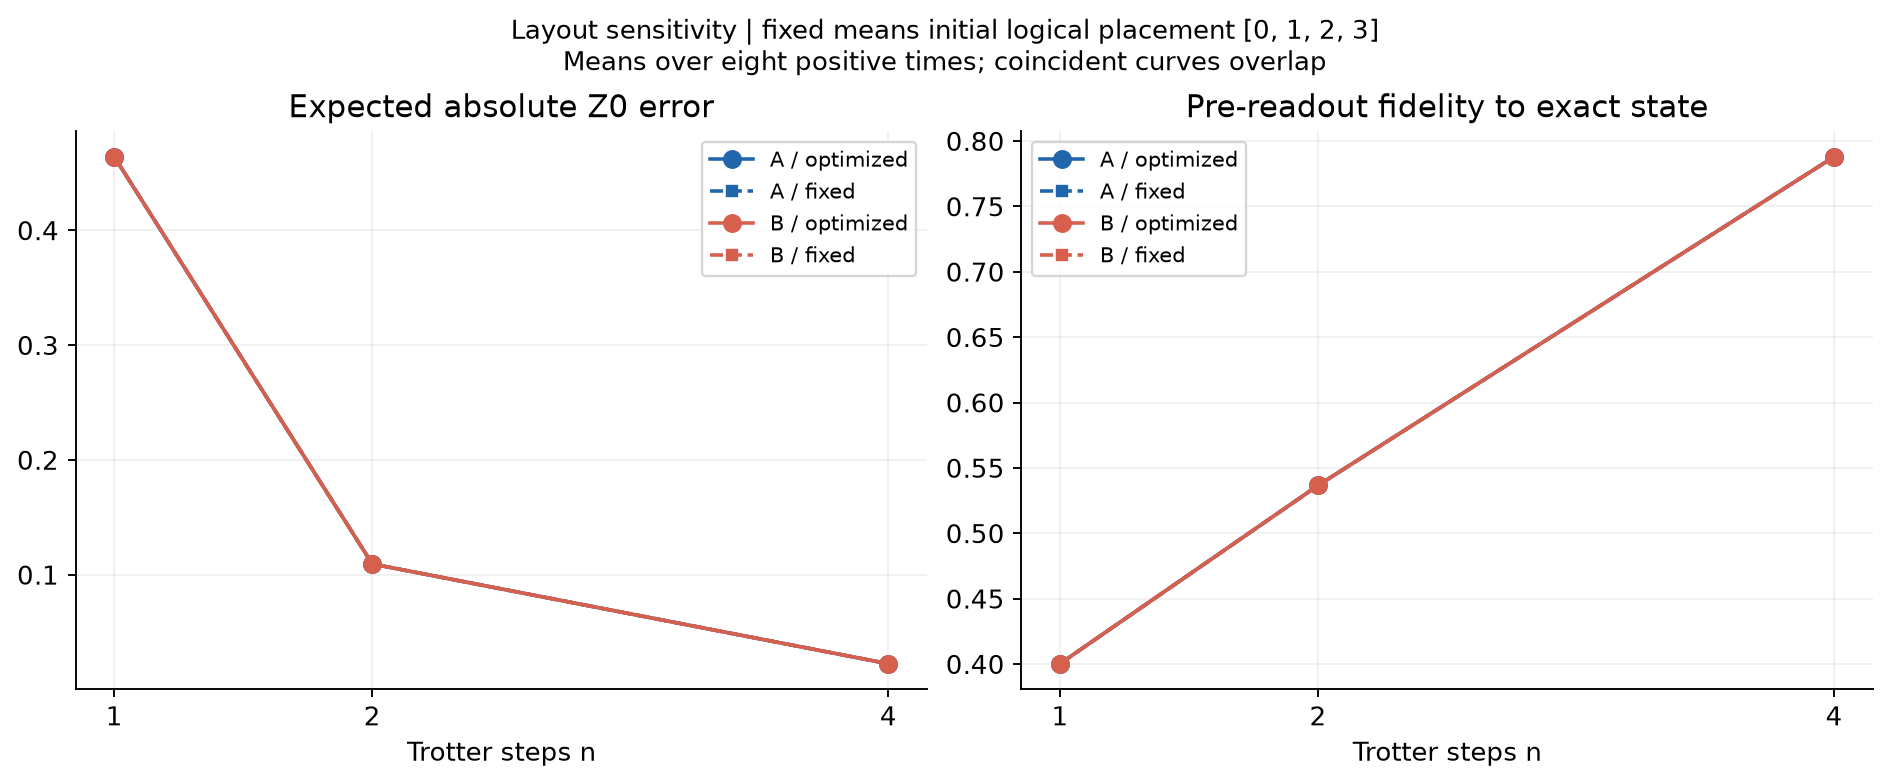

In [5]:
for name in ['processor_A_topology', 'processor_B_topology', 'z0_time_evolution',
             'error_vs_trotter_steps', 'depth_cx_swap_comparison', 'layout_sensitivity']:
    display(Image(filename=str(ROOT / 'results/figures' / (name + '.png'))))

## Results and bounded conclusions
Select the best n only among 1,2,4 for mean expected absolute Z0 error over positive times. Fidelity is a separate metric. These are synthetic channels, one compiler seed and two chosen graphs; there is no calibrated hardware model, universal optimum, or guaranteed B advantage.

In [6]:
best = summary.loc[summary.groupby(['processor', 'layout_mode']).total_expected_error.idxmin(),
                   ['processor', 'layout_mode', 'steps', 'total_expected_error']]
display(best)
print('Raw counts, routing audits, compiled circuits, states, CSV tables and figures regenerated.')

,processor,layout_mode,steps,total_expected_error
2,A,fixed,4,0.0225
5,A,optimized,4,0.0225
8,B,fixed,4,0.0225
11,B,optimized,4,0.0225


Raw counts, routing audits, compiled circuits, states, CSV tables and figures regenerated.
